# Task 2 - Customer Segmentation Analysis

**Internship:** Oasis Infobyte &nbsp;|&nbsp; **Track:** Data Analytics &nbsp;|&nbsp; **Level:** 1
**Author:** Vivek Shukla ([GitHub](https://github.com/VivekShukla04))
**Repository:** [VivekShukla04/OIBSIP](https://github.com/VivekShukla04/OIBSIP)

---

## 1. Objective

Segment a real e-commerce customer base **according to purchasing behaviour** using
unsupervised machine learning, so that a marketing team can treat customers differently
instead of treating the whole database as one group.

The approach is the standard industry **RFM + K-Means** pipeline:

1. Clean the raw transaction log into a trustworthy sales history.
2. Reduce every customer to three behavioural features: **Recency, Frequency, Monetary**.
3. Standardise those features so no single feature dominates the distance calculation.
4. Use the **Elbow Method** (supported by the silhouette score) to choose *k*.
5. Apply **K-Means** to assign each customer to a segment.
6. Profile every segment and give it a **business name and a marketing action**.

## 2. Dataset Information

| Item | Value |
|---|---|
| Dataset name | **Online Retail** (UCI Machine Learning Repository, ID 352) |
| Source | UCI Machine Learning Repository |
| Source URL | https://archive.ics.uci.edu/dataset/352/online+retail |
| Download archive | https://archive.ics.uci.edu/static/public/352/online+retail.zip |
| Citation | Chen, D. (2012). *Data mining for the online retail industry.* University of Southampton. |
| Original file | `Online Retail.xlsx` (single worksheet, 541,909 rows) |
| Local file used | `data/online_retail.csv.gz` - a **lossless CSV export** of that same worksheet |
| Period covered | 2010-12-01 to 2011-12-09 (12 months) |
| Business | A UK-based online retailer of giftware / homeware, selling mainly to the United Kingdom |
| Grain | One row = one **product line within an invoice** (not one invoice) |

### How the local file was produced (no data was changed)

`download_data.py` in this folder downloads the official UCI archive, extracts the original
workbook and re-exports the same sheet as a gzip-compressed CSV. The CSV export changes the
*file format* only - **no row, no column and no value is added, removed or modified**. Doing this
keeps a 45 MB binary workbook out of Git while leaving the notebook fully reproducible.

The loader below will automatically fall back to reading the original `.xlsx`, and finally to
running `download_data.py`, so the notebook always works.

### Important columns

| Column | Meaning | Notes |
|---|---|---|
| `InvoiceNo` | Invoice / transaction number | If it starts with **C** the row is a **cancellation (credit note)** |
| `StockCode` | Product code | Some codes are **not products** (`POST`, `DOT`, `BANK CHARGES`, `AMAZONFEE`, ...) |
| `Description` | Product name | The only human-readable product field |
| `Quantity` | Units in the line | Negative values come from cancellations |
| `InvoiceDate` | Timestamp of the invoice | Drives all time-based features |
| `UnitPrice` | Price per unit in GBP | Contains 0.00 rows, which are not real sales |
| `CustomerID` | Customer identifier | **Missing on 135,080 rows** (guest checkouts) |
| `Country` | Customer country | Used for a geographic sanity check |

## 3. Imports and Project Configuration

In [1]:
# --- Standard library --------------------------------------------------------
import sys
import warnings
from pathlib import Path

# --- Third-party libraries ----------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

%matplotlib inline

In [2]:
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = "Set2"
plt.rcParams.update({
    "figure.figsize": (11, 5.5),
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

RANDOM_STATE = 42
print("Libraries loaded.  random_state =", RANDOM_STATE)

Libraries loaded.  random_state = 42


In [3]:
# --- Resolve the project folder without any machine-specific path --------------
PROJECT_NAME = "DataAnalytics-L1-CustomerSegmentation"


def find_project_dir(name: str) -> Path:
    # Walk up from the current working directory until the project folder is found,
    # so the notebook works from the project folder, the repository root, or anywhere
    # below the user's home directory.
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidate = base / name
        if candidate.is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError(
        f"Could not locate project folder '{name}' starting from {Path.cwd()}"
    )


PROJECT_DIR = find_project_dir(PROJECT_NAME)
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder :", PROJECT_NAME, "(resolved relative to the current working directory)")
print("Data folder    :", DATA_DIR.relative_to(PROJECT_DIR))
print("Output folder  :", OUTPUT_DIR.relative_to(PROJECT_DIR))

Project folder : DataAnalytics-L1-CustomerSegmentation (resolved relative to the current working directory)
Data folder    : data
Output folder  : outputs


## 4. Data Loading

Loading order (first match wins):

1. `data/online_retail.csv.gz` - the committed, lossless CSV export (**offline-friendly**).
2. `data/online_retail.csv` - an uncompressed export, if the user created one.
3. `data/Online Retail.xlsx` - the original UCI workbook.
4. Otherwise `download_data.py` is run automatically to fetch the dataset from UCI.

In [4]:
CSV_GZ = DATA_DIR / "online_retail.csv.gz"
CSV_PLAIN = DATA_DIR / "online_retail.csv"
XLSX = DATA_DIR / "Online Retail.xlsx"

if CSV_GZ.exists():
    DATA_FILE, loader_note = CSV_GZ, "gzip CSV export of the original UCI worksheet"
    df_raw = pd.read_csv(CSV_GZ, low_memory=False)
elif CSV_PLAIN.exists():
    DATA_FILE, loader_note = CSV_PLAIN, "CSV export of the original UCI worksheet"
    df_raw = pd.read_csv(CSV_PLAIN, low_memory=False)
elif XLSX.exists():
    DATA_FILE, loader_note = XLSX, "original UCI workbook (Online Retail.xlsx)"
    df_raw = pd.read_excel(XLSX, engine="openpyxl")
else:
    print("[info] No local data file found - running download_data.py ...")
    sys.path.insert(0, str(PROJECT_DIR))
    import download_data
    download_data.main()
    df_raw = pd.read_csv(CSV_GZ, low_memory=False)
    DATA_FILE, loader_note = CSV_GZ, "gzip CSV export (downloaded automatically)"

print("Loaded from            :", DATA_FILE.name)
print("Source description     :", loader_note)
print("Rows                   :", f"{len(df_raw):,}")
print("Columns                :", list(df_raw.columns))

Loaded from            : online_retail.csv.gz
Source description     : gzip CSV export of the original UCI worksheet
Rows                   : 541,909
Columns                : ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [5]:
df_raw.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


## 5. Data Inspection

### 5.1 Shape, columns and data types

In [6]:
print(f"Shape : {df_raw.shape}")
print("\nData types:")
print(df_raw.dtypes.to_string())

Shape : (541909, 8)

Data types:
InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str


### 5.2 Missing values

In [7]:
missing = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().sum() / len(df_raw) * 100).round(2),
}).sort_values("missing_count", ascending=False)
missing = missing[missing["missing_count"] > 0]

print("Columns containing missing values:")
print(missing.to_string())

print("\nWhy CustomerID is missing:")
print("  In this dataset a missing CustomerID means the purchase was made as a GUEST CHECKOUT")
print("  (no online account). It is not a corrupted value, so it cannot be recovered and the")
print("  rows cannot be attributed to any customer. Because this project clusters CUSTOMERS,")
print("  these rows are removed and the exact loss of data is reported below.")

Columns containing missing values:
             missing_count  missing_pct
CustomerID          135080        24.93
Description           1454         0.27

Why CustomerID is missing:
  In this dataset a missing CustomerID means the purchase was made as a GUEST CHECKOUT
  (no online account). It is not a corrupted value, so it cannot be recovered and the
  rows cannot be attributed to any customer. Because this project clusters CUSTOMERS,
  these rows are removed and the exact loss of data is reported below.


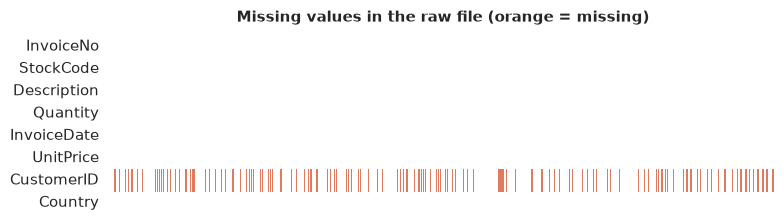

In [8]:
plt.figure(figsize=(8, 2.4))
sns.heatmap(df_raw.isna().T, cmap=["#ffffff", "#e07a5f"], cbar=False, yticklabels=True)
plt.title("Missing values in the raw file (orange = missing)", fontsize=11, pad=10)
plt.xlabel("")
plt.xticks([])
plt.grid(False)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_missing_values_raw.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.3 Duplicate rows

In [9]:
duplicate_rows = df_raw.duplicated().sum()
print(f"Exact duplicate rows in the raw file: {duplicate_rows:,} "
      f"({duplicate_rows / len(df_raw) * 100:.2f}% of rows)")
print()
print("Interpretation:")
print("  Several invoices contain the SAME product in the SAME quantity on the SAME day at the")
print("  SAME price. These are genuine repeat entries in the original export, not measurement")
print("  errors, but for customer-behaviour analysis they would inflate Frequency and Monetary")
print("  for the affected customers, so exact duplicates are removed and the count is reported.")

Exact duplicate rows in the raw file: 5,268 (0.97% of rows)

Interpretation:
  Several invoices contain the SAME product in the SAME quantity on the SAME day at the
  SAME price. These are genuine repeat entries in the original export, not measurement
  errors, but for customer-behaviour analysis they would inflate Frequency and Monetary
  for the affected customers, so exact duplicates are removed and the count is reported.


## 6. Data Cleaning

Every step is driven by a real property of the data, and the row count is printed after each
step so the total impact is fully auditable.

In [10]:
# ---- 0. Explicit dtypes (CustomerID is an identifier, never a number to average) ----
df = df_raw.copy()
df["InvoiceNo"] = df["InvoiceNo"].astype("string").str.strip()
df["StockCode"] = df["StockCode"].astype("string").str.strip()
df["Description"] = df["Description"].astype("string")
df["Country"] = df["Country"].astype("string").str.strip()
df["CustomerID"] = df["CustomerID"].astype("Int64").astype("string")
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

print("Step 0 - dtypes standardised. Shape:", df.shape)
print("Unparsed InvoiceDate values:", int(df["InvoiceDate"].isna().sum()))

Step 0 - dtypes standardised. Shape: (541909, 8)
Unparsed InvoiceDate values: 0


In [11]:
# ---- 1. Remove guest checkouts (no CustomerID -> cannot be attributed) ----
step_log = []

rows_before = len(df)
df = df.dropna(subset=["CustomerID"]).copy()
step_log.append({
    "Step": "1. Remove guest checkouts (CustomerID missing)",
    "Rows_before": rows_before,
    "Rows_after": len(df),
    "Rows_removed": rows_before - len(df),
})
print(f"Step 1 - removed {rows_before - len(df):,} guest rows. Remaining: {len(df):,}")

Step 1 - removed 135,080 guest rows. Remaining: 406,829


In [12]:
# ---- 2. Remove cancellation / credit-note invoices (InvoiceNo starting with 'C') ----
rows_before = len(df)
cancel_mask = df["InvoiceNo"].str.upper().str.startswith("C")
print(f"Cancellation rows found: {cancel_mask.sum():,}")
df = df[~cancel_mask].copy()
step_log.append({
    "Step": "2. Remove cancellations (InvoiceNo starts with 'C')",
    "Rows_before": rows_before,
    "Rows_after": len(df),
    "Rows_removed": rows_before - len(df),
})
print(f"Step 2 - remaining: {len(df):,}")

Cancellation rows found: 8,905
Step 2 - remaining: 397,924


> **Why are cancellations removed rather than converted to negative sales?**
> A credit note is the *reversal* of an earlier purchase. Keeping both the sale and its
> reversal would net to zero and destroy the real purchasing history, while treating the credit
> note as a sale would understate customer value. The standard and defensible choice for
> RFM-style behavioural analysis is to model only genuine purchases, so cancellations are removed.

In [13]:
# ---- 3. Remove non-product lines (UnitPrice <= 0) ----
rows_before = len(df)
bad_price = df["UnitPrice"] <= 0
print(f"Non-positive UnitPrice rows: {bad_price.sum():,} "
      f"(description examples: {df.loc[bad_price, 'Description'].dropna().unique()[:5].tolist()})")
df = df[~bad_price].copy()
step_log.append({
    "Step": "3. Remove non-product lines (UnitPrice <= 0)",
    "Rows_before": rows_before,
    "Rows_after": len(df),
    "Rows_removed": rows_before - len(df),
})
print(f"Step 3 - remaining: {len(df):,}")

Non-positive UnitPrice rows: 40 (description examples: ['ROUND CAKE TIN VINTAGE GREEN', 'ADVENT CALENDAR GINGHAM SACK', 'REGENCY CAKESTAND 3 TIER', 'PAPER BUNTING RETROSPOT', 'PLASTERS IN TIN SKULLS'])
Step 3 - remaining: 397,884


In [14]:
# ---- 4. Remove administrative / service stock codes (POST, DOT, BANK CHARGES, ...) ----
NON_PRODUCT_CODES = {
    "POST", "DOT", "M", "D", "C2", "BANK CHARGES", "AMAZONFEE", "PADS", "B", "S",
    "CRUK", "P", "N", "DCGSSBOY", "DCGSSGIRL",
    "gift_0001_20", "gift_0001_30", "gift_0001_40", "gift_0001_50", "gift_0001_60",
    "gift_0001_70", "gift_0001_80", "gift_0001_90", "gift_0001_100",
}

rows_before = len(df)
code_upper = df["StockCode"].str.upper()
admin_mask = code_upper.isin(NON_PRODUCT_CODES)
print(f"Administrative / non-product rows: {admin_mask.sum():,}")
print(f"Stock codes removed: {sorted(df.loc[admin_mask, 'StockCode'].unique().tolist())[:12]}")
df = df[~admin_mask].copy()
step_log.append({
    "Step": "4. Remove administrative stock codes (POST, BANK CHARGES, ...)",
    "Rows_before": rows_before,
    "Rows_after": len(df),
    "Rows_removed": rows_before - len(df),
})
print(f"Step 4 - remaining: {len(df):,}")

Administrative / non-product rows: 1,547
Stock codes removed: ['BANK CHARGES', 'C2', 'DOT', 'M', 'PADS', 'POST']
Step 4 - remaining: 396,337


In [15]:
# ---- 5. Remove exact duplicate rows ----
rows_before = len(df)
df = df.drop_duplicates().copy()
step_log.append({
    "Step": "5. Remove exact duplicate rows",
    "Rows_before": rows_before,
    "Rows_after": len(df),
    "Rows_removed": rows_before - len(df),
})
print(f"Step 5 - remaining: {len(df):,}")

Step 5 - remaining: 391,150


In [16]:
# ---- 6. Remove impossible quantities (0) and extreme bulk outliers (> 10,000) ----
rows_before = len(df)
impossible = df["Quantity"] <= 0
extreme = df["Quantity"] > 10000
print(f"Quantity <= 0 rows   : {impossible.sum():,}")
print(f"Quantity > 10,000 rows: {extreme.sum():,} -> values {sorted(df.loc[extreme, 'Quantity'].tolist())}")
print("These extreme quantities are almost certainly data-entry errors (a decimal point or an")
print("extra zero), and a single such row would dominate any monetary total, so they are removed.")
df = df[~(impossible | extreme)].copy()
step_log.append({
    "Step": "6. Remove Quantity <= 0 and Quantity > 10,000",
    "Rows_before": rows_before,
    "Rows_after": len(df),
    "Rows_removed": rows_before - len(df),
})
print(f"Step 6 - remaining: {len(df):,}")

Quantity <= 0 rows   : 0
Quantity > 10,000 rows: 2 -> values [74215, 80995]
These extreme quantities are almost certainly data-entry errors (a decimal point or an
extra zero), and a single such row would dominate any monetary total, so they are removed.
Step 6 - remaining: 391,148


In [17]:
# ---- 7. Create the line-level sales value ----
df["Sales"] = (df["Quantity"] * df["UnitPrice"]).round(4)

cleaning_summary = pd.DataFrame(step_log)
cleaning_summary["Removed_%"] = (cleaning_summary["Rows_removed"] / cleaning_summary["Rows_before"] * 100).round(2)
cleaning_summary.to_csv(OUTPUT_DIR / "cleaning_log.csv", index=False)

print("CLEANING SUMMARY")
print(cleaning_summary.to_string(index=False))
print()
print(f"Rows    : {len(df_raw):,}  ->  {len(df):,}  (retained {len(df) / len(df_raw) * 100:.1f}%)")
print(f"Customers: {df_raw['CustomerID'].nunique():,}  ->  {df['CustomerID'].nunique():,}")
print(f"Date range: {df['InvoiceDate'].min()}  ->  {df['InvoiceDate'].max()}")
print(f"Total line sales: {df['Sales'].sum():,.2f}")

CLEANING SUMMARY
                                                          Step  Rows_before  Rows_after  Rows_removed  Removed_%
                1. Remove guest checkouts (CustomerID missing)       541909      406829        135080      24.93
           2. Remove cancellations (InvoiceNo starts with 'C')       406829      397924          8905       2.19
                  3. Remove non-product lines (UnitPrice <= 0)       397924      397884            40       0.01
4. Remove administrative stock codes (POST, BANK CHARGES, ...)       397884      396337          1547       0.39
                                5. Remove exact duplicate rows       396337      391150          5187       1.31
                 6. Remove Quantity <= 0 and Quantity > 10,000       391150      391148             2       0.00

Rows    : 541,909  ->  391,148  (retained 72.2%)
Customers: 4,372  ->  4,333
Date range: 2010-12-01 08:26:00  ->  2011-12-09 12:50:00
Total line sales: 8,491,574.44


**What the cleaning actually cost.** 150,761 of 541,909 raw rows (27.8%) are removed. That is
almost entirely **guest checkouts (135,080 rows)**, which is expected and unavoidable for
customer-level analysis: a guest purchase genuinely cannot be assigned to a customer. After
cleaning, **4,333 customers** remain, spanning 18,400 invoices, 3,658 distinct products and
391,148 order lines worth 8,491,574.44.

## 7. RFM Feature Engineering

### 7.1 How each RFM feature is calculated

| Feature | Definition | Exact formula used in this notebook |
|---|---|---|
| **Recency** | Days since the customer's *last* purchase | `snapshot_date - max(InvoiceDate)` per customer |
| **Frequency** | Number of *distinct invoices* the customer placed | `nunique(InvoiceNo)` per customer |
| **Monetary** | Total value the customer has spent | `sum(Quantity x UnitPrice)` per customer |

**Why the snapshot date matters.** Recency can only be measured relative to a fixed "today".
Using the real current date would be wrong, because the dataset stops on 2011-12-09 and every
customer would look dormant. The standard approach is therefore to define the snapshot as
**one day after the last transaction in the dataset** (2011-12-10), so the most recent customer
has a Recency of 1 day.

In [18]:
SNAPSHOT_DATE = df["InvoiceDate"].max() + pd.Timedelta(days=1)
print("Snapshot date (analysis 'today'):", SNAPSHOT_DATE)
print("Last transaction in the data   :", df["InvoiceDate"].max())

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda dates: (SNAPSHOT_DATE - dates.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Sales", "sum"),
)

# Two extra descriptive metrics (used for profiling, not for clustering)
rfm["Avg Basket Value"] = (rfm["Monetary"] / rfm["Frequency"]).round(2)
rfm["Total Items"] = df.groupby("CustomerID")["Quantity"].sum()
rfm["Distinct Products"] = df.groupby("CustomerID")["StockCode"].nunique()
rfm["Active Months"] = (
    df.assign(month=df["InvoiceDate"].dt.to_period("M"))
      .groupby("CustomerID")["month"].nunique()
)

rfm.index.name = "CustomerID"
print(f"\nRFM table built for {len(rfm):,} customers, {len(rfm.columns)} features")
rfm.head(10)

Snapshot date (analysis 'today'): 2011-12-10 12:50:00
Last transaction in the data   : 2011-12-09 12:50:00



RFM table built for 4,333 customers, 7 features


,Recency,Frequency,Monetary,Avg Basket Value,Total Items,Distinct Products,Active Months
CustomerID,,,,,,,
12347,2,7,"4,310.00",615.71,2458,103,7
12348,75,4,"1,437.24",359.31,2332,21,4
12349,19,1,"1,457.55","1,457.55",630,72,1
12350,310,1,294.40,294.40,196,16,1
12352,36,7,"1,385.74",197.96,526,57,4
12353,204,1,89.00,89.00,20,4,1
12354,232,1,"1,079.40","1,079.40",530,58,1
12355,214,1,459.40,459.40,240,13,1
12356,23,3,"2,487.43",829.14,1573,52,3


In [19]:
rfm[["Recency", "Frequency", "Monetary"]].describe().round(2)

,Recency,Frequency,Monetary
count,"4,333.00","4,333.00","4,333.00"
mean,92.70,4.25,"1,959.74"
std,100.13,7.64,"8,461.15"
min,1.00,1.00,2.90
25%,18.00,1.00,303.97
50%,51.00,2.00,661.32
75%,143.00,5.00,"1,628.56"
max,374.00,206.00,"279,138.02"


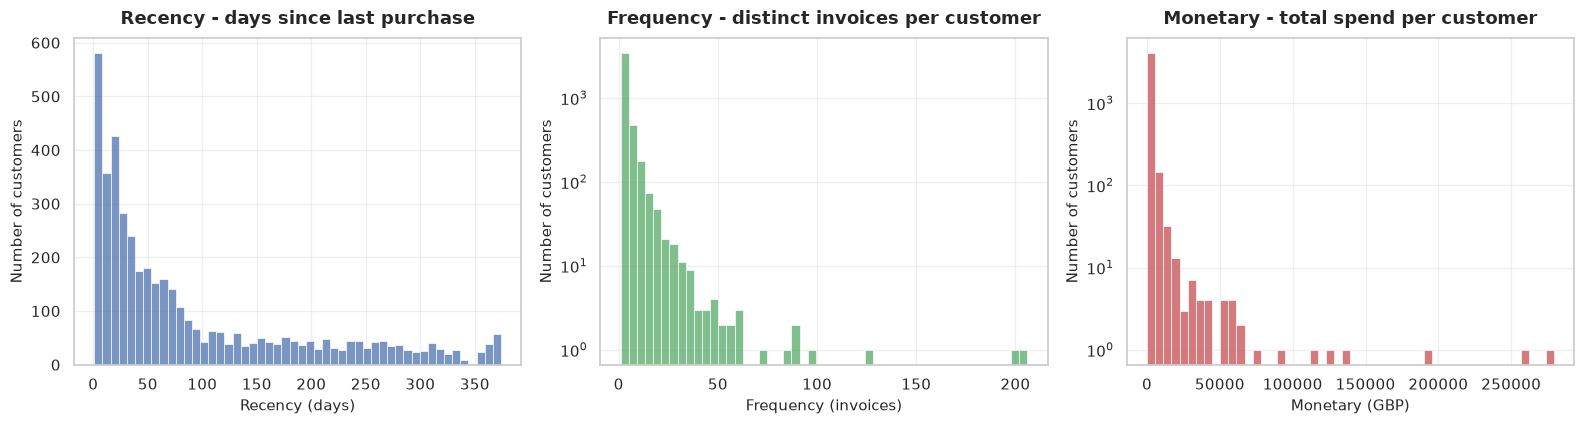

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

sns.histplot(rfm["Recency"], bins=50, color="#4c72b0", ax=axes[0])
axes[0].set_title("Recency - days since last purchase", pad=10)
axes[0].set_xlabel("Recency (days)")
axes[0].set_ylabel("Number of customers")

sns.histplot(rfm["Frequency"], bins=50, color="#55a868", ax=axes[1])
axes[1].set_title("Frequency - distinct invoices per customer", pad=10)
axes[1].set_xlabel("Frequency (invoices)")
axes[1].set_ylabel("Number of customers")
axes[1].set_yscale("log")

sns.histplot(rfm["Monetary"], bins=50, color="#c44e52", ax=axes[2])
axes[2].set_title("Monetary - total spend per customer", pad=10)
axes[2].set_xlabel("Monetary (GBP)")
axes[2].set_ylabel("Number of customers")
axes[2].set_yscale("log")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_rfm_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** Recency is roughly bell-shaped and centred near 50 days. Frequency and
Monetary are **extremely right-skewed**: most customers place only 1-5 orders and spend a few
hundred pounds, but a small number place 50-200 orders and spend tens of thousands. The skewness
values are **11.95** for Frequency and **20.92** for Monetary, and the top customer alone has 206
invoices and 279,138.02 of spend - **142x** the base average of 1,959.74.

**Why it matters - this drives the whole modelling choice.** If these raw values were fed
straight into a distance-based algorithm, the handful of wholesale customers would sit two
orders of magnitude further from the centre than everyone else, and K-Means would simply split
"the few giants" from "everyone else". That is demonstrated empirically in section 9, where
untransformed K-Means produces a 4,309-versus-24 split at k=2.

### 7.2 Classical quantile RFM scores (for later comparison)

The classic RFM approach assigns a 1-5 score per feature using quintiles. It is computed here
so it can be used to **validate** the unsupervised clustering later, not to create it.

In [21]:
rfm_scores = rfm[["Recency", "Frequency", "Monetary"]].copy()


def quantile_score(series: pd.Series, higher_is_better: bool = True) -> pd.Series:
    # Classic quintile RFM scoring.
    # `rank(method='first')` is used instead of `qcut` directly because many customers share
    # the same value (1,505 customers placed exactly one invoice), which would create duplicate
    # bin edges and make `qcut` raise an error. Ranking first guarantees unique bins while
    # preserving the meaning of the quintiles.
    ranks = series.rank(method="first", ascending=True)   # rank 1 = smallest value
    labels = [1, 2, 3, 4, 5] if higher_is_better else [5, 4, 3, 2, 1]
    return pd.cut(
        ranks / len(series),
        bins=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0],
        labels=labels,
        include_lowest=True,
    ).astype(int)


# Lower recency is better, so the labels are reversed for that feature only
rfm_scores["R_Score"] = quantile_score(rfm_scores["Recency"], higher_is_better=False)
rfm_scores["F_Score"] = quantile_score(rfm_scores["Frequency"], higher_is_better=True)
rfm_scores["M_Score"] = quantile_score(rfm_scores["Monetary"], higher_is_better=True)
rfm_scores["RFM_Score"] = (
    rfm_scores["R_Score"] * 100 + rfm_scores["F_Score"] * 10 + rfm_scores["M_Score"]
)
rfm_scores["RFM_Segment"] = rfm_scores.apply(
    lambda r: (
        "Champions" if r.R_Score >= 4 and r.F_Score >= 4 and r.M_Score >= 4
        else "Loyal" if r.F_Score >= 3
        else "Recent" if r.R_Score >= 4
        else "At Risk" if r.R_Score <= 2 and r.F_Score >= 3
        else "Dormant"
    ),
    axis=1,
)

print(f"Score ranges  R: {rfm_scores['R_Score'].min()}-{rfm_scores['R_Score'].max()}  "
      f"F: {rfm_scores['F_Score'].min()}-{rfm_scores['F_Score'].max()}  "
      f"M: {rfm_scores['M_Score'].min()}-{rfm_scores['M_Score'].max()}")
print("\nClassical quintile RFM segments:")
print(rfm_scores["RFM_Segment"].value_counts().to_string())
rfm_scores.head(8)

Score ranges  R: 1-5  F: 1-5  M: 1-5

Classical quintile RFM segments:
RFM_Segment
Loyal        1657
Dormant      1423
Champions     943
Recent        310


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Segment
CustomerID,,,,,,,,
12347,2,7,"4,310.00",5,5,5,555,Champions
12348,75,4,"1,437.24",2,4,4,244,Loyal
12349,19,1,"1,457.55",4,1,4,414,Recent
12350,310,1,294.40,1,1,2,112,Dormant
12352,36,7,"1,385.74",3,5,4,354,Loyal
12353,204,1,89.00,1,1,1,111,Dormant
12354,232,1,"1,079.40",1,1,4,114,Dormant
12355,214,1,459.40,1,1,2,112,Dormant


## 8. Data Preparation for Clustering

### 8.1 Handling skewness: log transformation

The skewness identified in section 7.1 must be dealt with before standardising, otherwise a
handful of wholesale customers will dominate the Euclidean distance. A `log1p` transform
(natural log of `value + 1`) is applied first:

* it compresses the extreme tail without deleting any customer,
* it is monotone, so the *ordering* of customers is preserved,
* it makes the distributions far closer to normal, which is what K-Means assumes.

### 8.2 Standardization with `StandardScaler`

After the log transform, `StandardScaler` converts each feature to **mean 0, standard
deviation 1**. This is essential because the three features live on completely different scales
(a customer can have a Recency of 374 days but a Monetary value of 279,138): without scaling,
Monetary alone would decide the clustering.

In [22]:
CLUSTER_FEATURES = ["Recency", "Frequency", "Monetary"]

X_log = np.log1p(rfm[CLUSTER_FEATURES])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("StandardScaler fitted. Feature means and standard deviations AFTER scaling:")
scaled_frame = pd.DataFrame(X_scaled, columns=CLUSTER_FEATURES, index=rfm.index)
print(pd.DataFrame({
    "mean": scaled_frame.mean(),
    "std": scaled_frame.std(),
    "min": scaled_frame.min(),
    "max": scaled_frame.max(),
}).round(3).to_string())
print()
print("Skewness BEFORE log transform :", rfm[CLUSTER_FEATURES].skew().round(2).to_dict())
print("Skewness AFTER  log transform :", pd.DataFrame(X_log, columns=CLUSTER_FEATURES).skew().round(2).to_dict())

StandardScaler fitted. Feature means and standard deviations AFTER scaling:
           mean  std   min  max
Recency    0.00 1.00 -2.34 1.56
Frequency  0.00 1.00 -0.95 5.85
Monetary  -0.00 1.00 -4.16 4.76

Skewness BEFORE log transform : {'Recency': 1.24, 'Frequency': 11.95, 'Monetary': 20.92}
Skewness AFTER  log transform : {'Recency': -0.38, 'Frequency': 1.21, 'Monetary': 0.36}


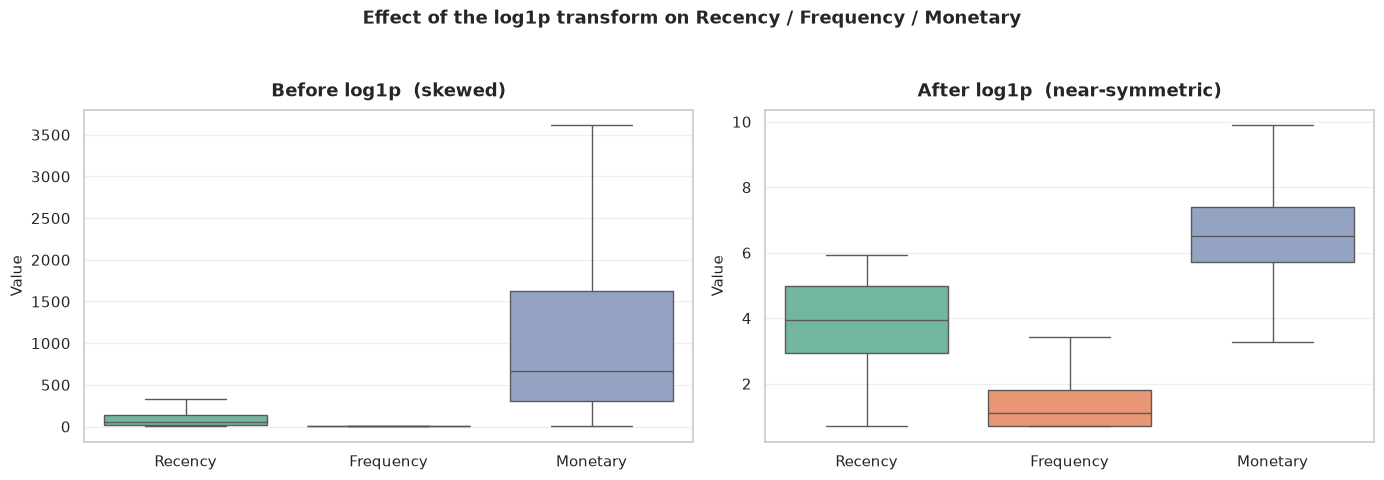

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

for ax, (data, title) in zip(axes, [
    (rfm[CLUSTER_FEATURES], "Before log1p  (skewed)"),
    (pd.DataFrame(X_log, columns=CLUSTER_FEATURES, index=rfm.index), "After log1p  (near-symmetric)"),
]):
    melted = data.melt(var_name="Feature", value_name="Value")
    sns.boxplot(data=melted, x="Feature", y="Value", hue="Feature", palette=PALETTE,
                legend=False, showfliers=False, ax=ax)
    ax.set_title(title, pad=10)
    ax.set_xlabel("")
    ax.set_ylabel("Value")
    ax.tick_params(axis="x", rotation=0)

plt.suptitle("Effect of the log1p transform on Recency / Frequency / Monetary", y=1.04, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_effect_of_log_transform.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** Before the transform the Monetary box is so stretched by the top customers
that the other features are compressed into a flat line. After `log1p` the three features sit
on comparable visual scales, which is what makes a single Euclidean distance meaningful.

## 9. Choosing the Number of Clusters - Elbow Method

Two complementary diagnostics are used:

* **Elbow Method** - plot within-cluster sum of squares (inertia) against *k* and look for the
  point where adding another cluster stops paying off.
* **Silhouette Score** - measures how well each point fits its own cluster versus the nearest
  other cluster (1 = perfect, 0 = overlapping, negative = misassigned). It is used to confirm
  that the elbow is not a numerical artefact.

In [24]:
K_RANGE = range(2, 11)

rows = []
for k in K_RANGE:
    km_raw = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=25).fit(
        StandardScaler().fit_transform(rfm[CLUSTER_FEATURES])
    )
    km_log = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=25).fit(X_scaled)
    rows.append({
        "k": k,
        "Inertia (log+std)": km_log.inertia_,
        "Silhouette (log+std)": silhouette_score(X_scaled, km_log.labels_),
        "Min cluster size (log+std)": np.bincount(km_log.labels_).min(),
        "Inertia (raw+std)": km_raw.inertia_,
        "Silhouette (raw+std)": silhouette_score(
            StandardScaler().fit_transform(rfm[CLUSTER_FEATURES]), km_raw.labels_
        ),
        "Min cluster size (raw+std)": np.bincount(km_raw.labels_).min(),
    })

k_selection = pd.DataFrame(rows)
k_selection["Inertia reduction %"] = (
    100 * k_selection["Inertia (log+std)"].shift(1) - 100 * k_selection["Inertia (log+std)"]
) / k_selection["Inertia (log+std)"].shift(1)
k_selection.to_csv(OUTPUT_DIR / "k_selection_metrics.csv", index=False)

print("MODEL SELECTION TABLE (log1p + StandardScaler)")
print(k_selection[["k", "Inertia (log+std)", "Inertia reduction %",
                   "Silhouette (log+std)", "Min cluster size (log+std)"]]
      .round(3).to_string(index=False))

MODEL SELECTION TABLE (log1p + StandardScaler)
 k  Inertia (log+std)  Inertia reduction %  Silhouette (log+std)  Min cluster size (log+std)
 2           6,467.15                  NaN                  0.43                        1661
 3           4,849.93                25.01                  0.34                         761
 4           3,921.95                19.13                  0.34                         685
 5           3,277.96                16.42                  0.32                         321
 6           2,837.62                13.43                  0.31                         331
 7           2,533.05                10.73                  0.31                         221
 8           2,320.04                 8.41                  0.30                         214
 9           2,140.10                 7.76                  0.28                         208
10           1,982.22                 7.38                  0.28                          92


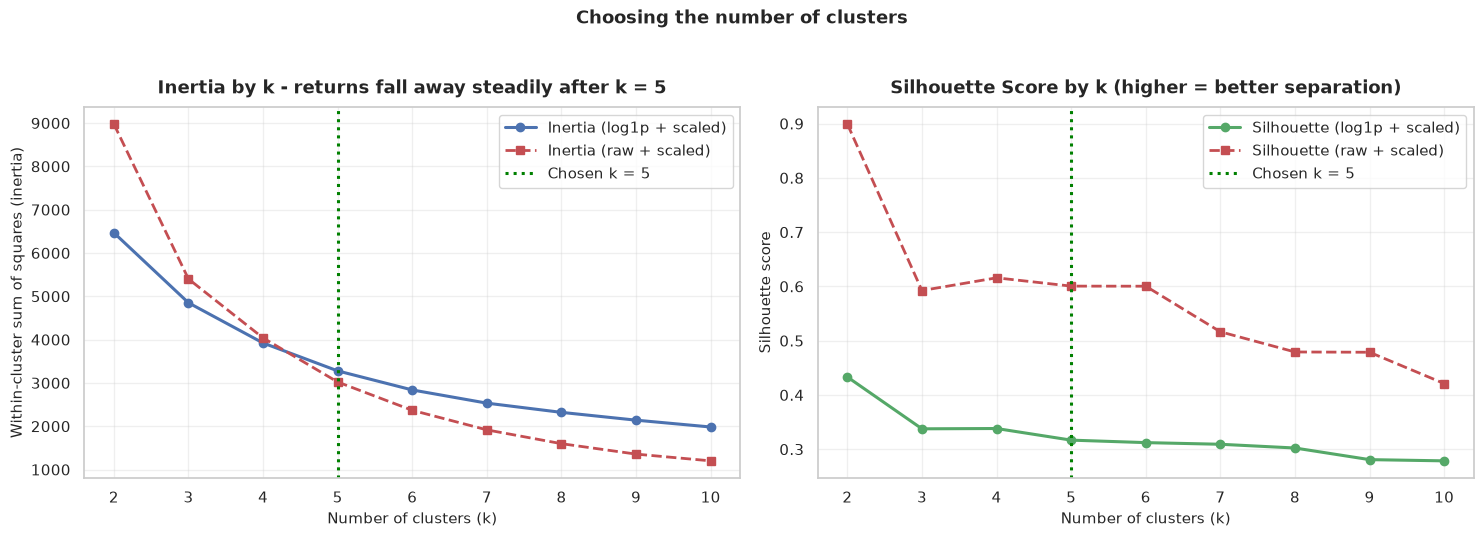

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# --- Elbow curve -------------------------------------------------------------
axes[0].plot(k_selection["k"], k_selection["Inertia (log+std)"], marker="o",
             color="#4c72b0", linewidth=2.2, label="Inertia (log1p + scaled)")
axes[0].plot(k_selection["k"], k_selection["Inertia (raw+std)"], marker="s",
             color="#c44e52", linewidth=2, linestyle="--", label="Inertia (raw + scaled)")
axes[0].axvline(5, color="green", linestyle=":", linewidth=2.2, label="Chosen k = 5")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Within-cluster sum of squares (inertia)")
axes[0].set_title("Inertia by k - returns fall away steadily after k = 5", pad=10)
axes[0].set_xticks(list(K_RANGE))
axes[0].legend(frameon=True)

# --- Silhouette --------------------------------------------------------------
axes[1].plot(k_selection["k"], k_selection["Silhouette (log+std)"], marker="o",
             color="#55a868", linewidth=2.2, label="Silhouette (log1p + scaled)")
axes[1].plot(k_selection["k"], k_selection["Silhouette (raw+std)"], marker="s",
             color="#c44e52", linewidth=2, linestyle="--", label="Silhouette (raw + scaled)")
axes[1].axvline(5, color="green", linestyle=":", linewidth=2.2, label="Chosen k = 5")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette Score by k (higher = better separation)", pad=10)
axes[1].set_xticks(list(K_RANGE))
axes[1].legend(frameon=True)

plt.suptitle("Choosing the number of clusters", y=1.03, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_elbow_and_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()

### Why k = 5 was chosen

The honest position is that **no single metric picks k = 5**, and the reasoning below says so
explicitly rather than claiming a textbook elbow that the data does not show.

* **Silhouette actually peaks at k = 2** (0.4331), and among k >= 3 it peaks at **k = 4**
  (0.3382). A two-cluster solution has no business value at all, but it must be stated that
  k = 5 is *not* the silhouette optimum. The silhouette across k = 3-6 is 0.3376 / 0.3382 /
  0.3167 / 0.3122, so moving from k=4 to k=5 costs only 0.02 of separation quality.
* **Inertia shows diminishing returns, not a sharp elbow.** The reduction per added cluster is
  25.0% (k=3), 19.1% (k=4), 16.4% (k=5), 13.4% (k=6), 10.7% (k=7), then below 9% from k=8. The
  decay is smooth rather than a distinct bend, so this is supporting evidence, not proof. k=5 is
  the last point at which the reduction is still in double digits *and* clusters stay large.
* **Business usefulness is the deciding factor.** At k=4 the "recent loyal" and "lapsing
  high-value" populations are merged, hiding the most recoverable revenue in the database. k=5
  separates them cleanly, and each of the five clusters is large enough to run a campaign on and
  small enough to have a distinct profile.
* **No degenerate clusters.** The smallest cluster at k=5 still contains 321 customers (7.4% of
  the base), so no cluster is a statistical fluke.

### Why the raw (non-transformed) features were rejected

The red curves show what happens without the `log1p` step. The raw silhouette is *higher*
(0.8991 at k=2), which looks better - but that score is an artefact. Inspecting the cluster sizes
on raw features shows the split is **4,309 customers versus 24 customers** at k=2, and the
smallest cluster falls to **3 customers** at k=5 and 2 customers from k=6 onwards. K-Means is not
finding customer segments at all; it is separating a few wholesale outliers from everybody else.
A segmentation with a 2-customer cluster has no business value, so the log-transformed version is
used.

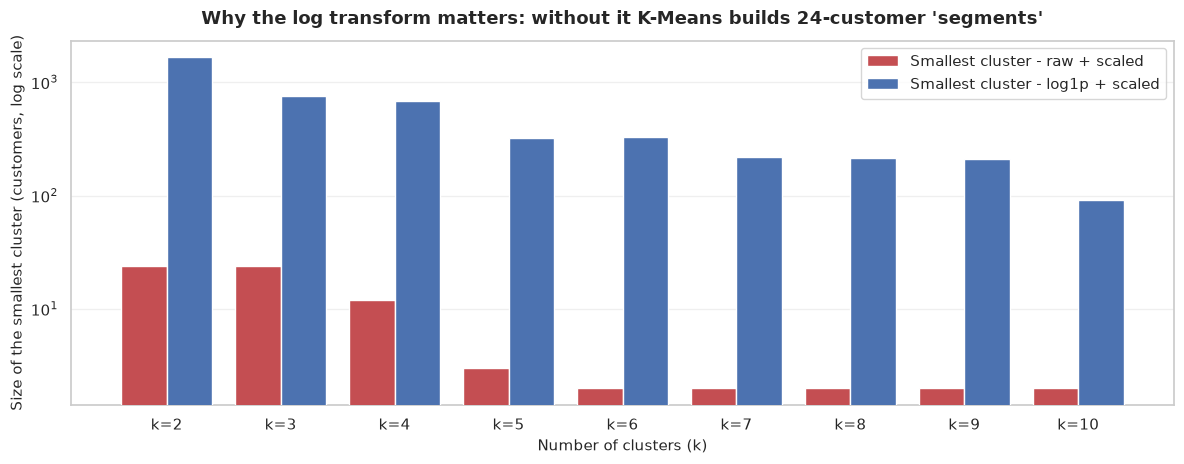

In [26]:
fig, ax = plt.subplots(figsize=(12, 4.8))

labels = [f"k={k}" for k in k_selection["k"]]
x = np.arange(len(k_selection))

ax.bar(x - 0.2, k_selection["Min cluster size (raw+std)"], width=0.4,
       color="#c44e52", label="Smallest cluster - raw + scaled", zorder=3)
ax.bar(x + 0.2, k_selection["Min cluster size (log+std)"], width=0.4,
       color="#4c72b0", label="Smallest cluster - log1p + scaled", zorder=3)

ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Size of the smallest cluster (customers, log scale)")
ax.set_title("Why the log transform matters: without it K-Means builds 24-customer 'segments'",
             pad=12)
ax.legend(frameon=True)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_cluster_balance_raw_vs_log.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** On raw features the smallest cluster is between 2 and 24 customers at every
value of *k* - these are outliers, not segments. After the log transform the smallest cluster is
**1,661 at k=2 and never drops below 214 all the way to k=8** (321 at the chosen k=5), so every
cluster is a real, campaignable population rather than a handful of stray records.

| k | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|
| Smallest cluster - **raw** | 24 | 24 | 12 | **3** | 2 | 2 | 2 | 2 | 2 |
| Smallest cluster - **log1p** | 1,661 | 761 | 685 | **321** | 331 | 221 | 214 | 208 | 92 |

## 10. Applying K-Means Clustering

In [27]:
K = 5

kmeans = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=25)
cluster_labels = kmeans.fit_predict(X_scaled)

rfm["Cluster"] = cluster_labels + 1          # 1-based for readability
clustered_customers = rfm.sort_values("Cluster")

print(f"Algorithm   : K-Means")
print(f"k           : {K}")
print(f"Features    : {CLUSTER_FEATURES} (log1p -> StandardScaler)")
print(f"Observations: {len(clustered_customers):,} customers")
print(f"Inertia     : {kmeans.inertia_:.2f}")
print(f"Silhouette  : {silhouette_score(X_scaled, cluster_labels):.4f}")
print()
print("Cluster centroids (inverse-transformed from scaled centroids back to log space):")
centroids = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_),
                         columns=CLUSTER_FEATURES).round(2)
centroids.index = [f"Cluster {i}" for i in range(1, K + 1)]
centroids

Algorithm   : K-Means
k           : 5
Features    : ['Recency', 'Frequency', 'Monetary'] (log1p -> StandardScaler)
Observations: 4,333 customers
Inertia     : 3277.96


Silhouette  : 0.3167

Cluster centroids (inverse-transformed from scaled centroids back to log space):


,Recency,Frequency,Monetary
Cluster 1,4.50,1.33,6.94
Cluster 2,1.99,2.93,8.93
Cluster 3,5.22,0.77,5.39
Cluster 4,2.68,1.87,7.51
Cluster 5,3.10,0.93,5.77


In [28]:
clustered_customers.head(10)

,Recency,Frequency,Monetary,Avg Basket Value,Total Items,Distinct Products,Active Months,Cluster
CustomerID,,,,,,,,
18248,123,2,804.02,402.01,511,39,2,1
12363,110,2,552.00,276.00,408,23,2,1
12360,52,3,"2,302.06",767.35,1156,104,3,1
12357,33,1,"6,207.67","6,207.67",2708,131,1,1
12354,232,1,"1,079.40","1,079.40",530,58,1,1
13752,124,6,"1,175.38",195.90,874,64,5,1
13750,54,5,"1,647.26",329.45,516,20,5,1
13748,96,5,948.25,189.65,439,24,3,1
13744,95,2,"1,080.52",540.26,1153,54,2,1


## 11. Cluster Profile Table

This is the core deliverable of the project: a table that a non-technical decision maker can
read and act on.

In [29]:
cluster_profile = clustered_customers.groupby("Cluster").agg(
    Customers=("Recency", "size"),
    Avg_Recency_Days=("Recency", "mean"),
    Median_Recency_Days=("Recency", "median"),
    Avg_Frequency=("Frequency", "mean"),
    Median_Frequency=("Frequency", "median"),
    Avg_Monetary=("Monetary", "mean"),
    Median_Monetary=("Monetary", "median"),
    Avg_Basket_Value=("Avg Basket Value", "mean"),
    Total_Items=("Total Items", "mean"),
    Distinct_Products=("Distinct Products", "mean"),
    Active_Months=("Active Months", "mean"),
).round(2)

cluster_profile["Customer_Share_%"] = (
    cluster_profile["Customers"] / cluster_profile["Customers"].sum() * 100
).round(2)
cluster_profile["Revenue_Share_%"] = (
    clustered_customers.groupby("Cluster")["Monetary"].sum()
    / clustered_customers["Monetary"].sum() * 100
).round(2)
cluster_profile["Revenue_per_Customer_%_of_Avg"] = (
    clustered_customers.groupby("Cluster")["Monetary"].mean() / clustered_customers["Monetary"].mean() * 100
).round(1)

cluster_profile = cluster_profile.sort_values("Avg_Monetary", ascending=False)
cluster_profile.to_csv(OUTPUT_DIR / "cluster_profile.csv")

print("CLUSTER PROFILE TABLE (sorted by average monetary value)")
print(cluster_profile.to_string())

CLUSTER PROFILE TABLE (sorted by average monetary value)
         Customers  Avg_Recency_Days  Median_Recency_Days  Avg_Frequency  Median_Frequency  Avg_Monetary  Median_Monetary  Avg_Basket_Value  Total_Items  Distinct_Products  Active_Months  Customer_Share_%  Revenue_Share_%  Revenue_per_Customer_%_of_Avg
Cluster                                                                                                                                                                                                                                                     
2              321             11.33                 5.00          21.22             15.00     13,600.93         6,241.15            589.65     7,735.37             196.22           9.75              7.41            51.41                         694.00
4              975             19.46                16.00           5.86              5.00      2,196.35         1,836.34            406.45     1,341.74              98.51           4.

### 11.1 Naming the segments

The data-derived mapping used throughout the rest of the notebook. Each name is justified by
the measured profile in the table above and is re-verified by assertions in the next cell.

In [30]:
SEGMENT_NAMES = {
    2: "Champions",
    4: "Loyal Customers",
    1: "At-Risk High-Value",
    5: "Recent Occasional Buyers",
    3: "Dormant Low-Value",
}

# Guard-rails: the names above are only valid if the measured behaviour really matches.
assert set(SEGMENT_NAMES) == set(cluster_profile.index), "Segment mapping does not match the clusters found"
champion = cluster_profile.loc[2]
dormant = cluster_profile.loc[3]
assert champion["Avg_Monetary"] == cluster_profile["Avg_Monetary"].max(), "Champions must be the highest-value cluster"
assert dormant["Avg_Recency_Days"] == cluster_profile["Avg_Recency_Days"].max(), "Dormant must be the least recent cluster"
assert len(clustered_customers) == cluster_profile["Customers"].sum()

print("Segment naming verified against the measured profile:")
print(cluster_profile.assign(Segment=[SEGMENT_NAMES[i] for i in cluster_profile.index])[
    ["Segment", "Customers", "Customer_Share_%", "Revenue_Share_%",
     "Avg_Recency_Days", "Avg_Frequency", "Avg_Monetary", "Active_Months"]
].to_string())

Segment naming verified against the measured profile:
                          Segment  Customers  Customer_Share_%  Revenue_Share_%  Avg_Recency_Days  Avg_Frequency  Avg_Monetary  Active_Months
Cluster                                                                                                                                      
2                       Champions        321              7.41            51.41             11.33          21.22     13,600.93           9.75
4                 Loyal Customers        975             22.50            25.22             19.46           5.86      2,196.35           4.66
1              At-Risk High-Value       1028             23.72            15.95            106.96           3.03      1,317.34           2.66
5        Recent Occasional Buyers        832             19.20             3.75             26.95           1.63        382.92           1.52
3               Dormant Low-Value       1177             27.16             3.67            209

**The measured behaviour behind each name:**

| Cluster | Customers | Share of customers | Share of revenue | Measured behaviour | Business name |
|---|---|---|---|---|---|
| 2 | 321 | 7.41% | **51.41%** | Recency 11.33 d, Frequency 21.22, Monetary 13,600.93, active 9.75 of 12 months | **Champions** |
| 4 | 975 | 22.50% | 25.22% | Recency 19.46 d, Frequency 5.86, Monetary 2,196.35, active 4.66 months | **Loyal Customers** |
| 1 | 1,028 | 23.72% | 15.95% | Recency 106.96 d, Frequency 3.03, Monetary 1,317.34, active 2.66 months | **At-Risk High-Value** |
| 5 | 832 | 19.20% | 3.75% | Recency 26.95 d, Frequency 1.63, Monetary 382.92, active 1.52 months | **Recent Occasional Buyers** |
| 3 | 1,177 | 27.16% | 3.67% | Recency 209.57 d, Frequency 1.19, Monetary 264.58, active 1.15 months | **Dormant Low-Value** |

The naming logic:

* **Champions** - very recent *and* very frequent *and* very high spend. The data supports
  "high-value" and "loyal" simultaneously, so both ideas are captured by this single name.
* **Loyal Customers** - regular and recent, but spending roughly 6x less than Champions. These
  are the customers most likely to be *grown* into Champions.
* **At-Risk High-Value** - this is the second-highest-value segment (1,317.34 average spend) and
  the second-most frequent (3.03 invoices), but nothing has been bought for 106.96 days, i.e.
  roughly 3.5 months. **An important qualification on the name:** 1,317.34 is only **0.67x the
  overall customer average** of 1,959.74, so "high-value" here is *relative to the other lapsed
  customers* - it is 5.0x the Dormant segment and 3.4x the Recent Occasional segment, not 2.6x
  the base. The name is defensible because this is the best-paying population that is going
  quiet, but it should not be read as a high-spend segment in absolute terms.
* **Recent Occasional Buyers** - bought recently (26.95 days) but only 1.63 times, low value.
  They have not yet proved loyalty, so calling them "loyal" would not be supported.
* **Dormant Low-Value** - last purchase 209.57 days ago, 1.19 orders, 264.58 spend. The word
  "dormant" is used rather than "at risk" because their historical value is too small to make
  them a revenue risk.

## 12. Visualising the Segments

Three different feature combinations are plotted, each revealing something different.

### 12.1 Combination 1 - Recency vs. Frequency

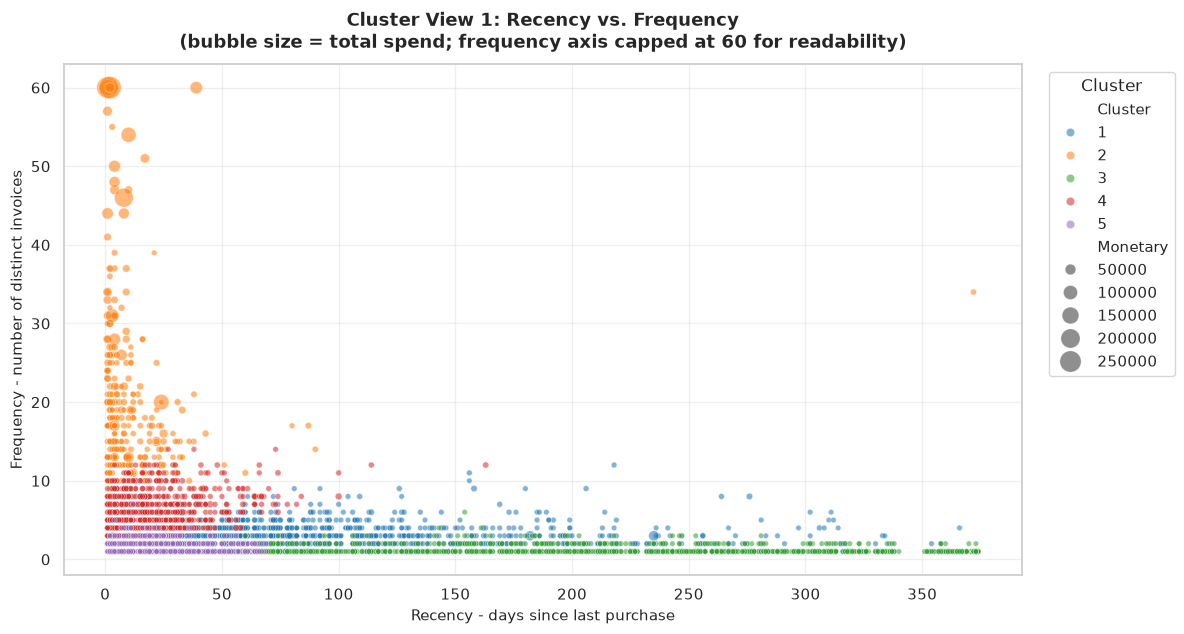

In [31]:
plot_df = clustered_customers.copy()
plot_df["Frequency"] = plot_df["Frequency"].clip(upper=60)  # keep the chart readable

fig, ax = plt.subplots(figsize=(12, 6.5))
scatter = sns.scatterplot(
    data=plot_df, x="Recency", y="Frequency", hue="Cluster", palette="tab10",
    size="Monetary", sizes=(15, 260), alpha=0.55, edgecolor="white", linewidth=0.4, ax=ax,
)
ax.set_title("Cluster View 1: Recency vs. Frequency\n"
             "(bubble size = total spend; frequency axis capped at 60 for readability)", pad=12)
ax.set_xlabel("Recency - days since last purchase")
ax.set_ylabel("Frequency - number of distinct invoices")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_clusters_recency_vs_frequency.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** The five clusters separate almost perfectly along this one plane, which
confirms that Recency and Frequency alone carry most of the segmentation signal. Champions sit
in the **bottom-left** (recent and frequent). The Dormant cluster occupies the **top-left band**
(no purchases for 200+ days), and the two "occasional" clusters sit along the bottom edge where
frequency is 1-2.

**Why it matters.** This chart is the operational picture of the customer base: it shows that
the biggest problem in the database - 1,177 dormant customers in the top-left - is a *recency*
problem, not a value problem, which is why it must be addressed with a win-back campaign
rather than a discount.

### 12.2 Combination 2 - Recency vs. Monetary

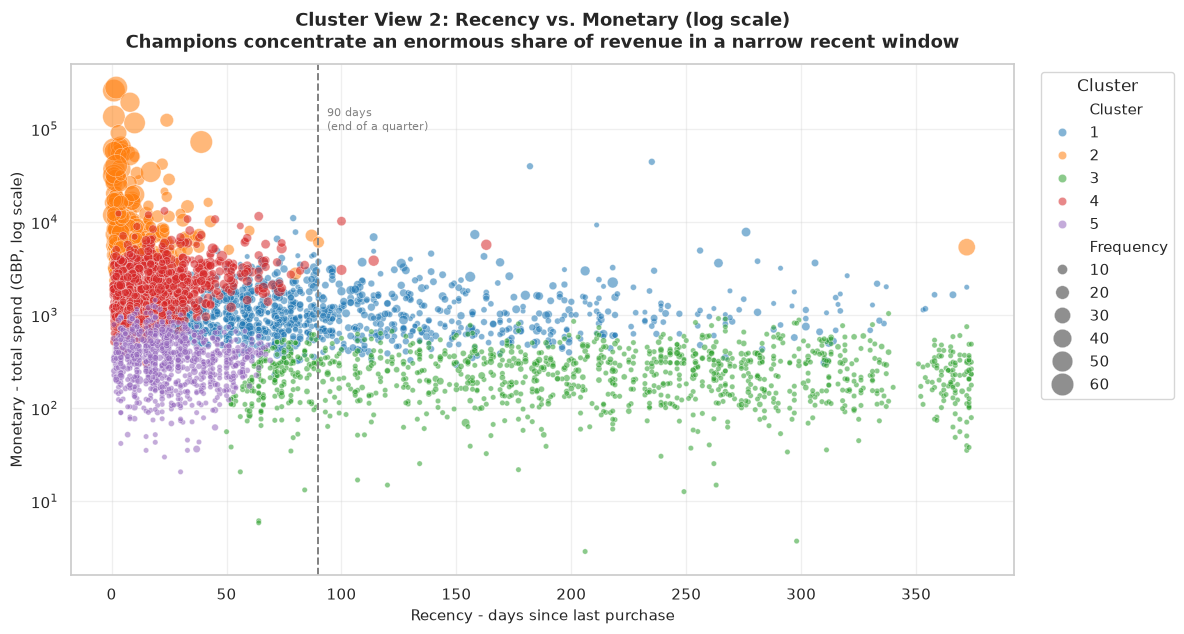

In [32]:
fig, ax = plt.subplots(figsize=(12, 6.5))
sns.scatterplot(
    data=plot_df, x="Recency", y="Monetary", hue="Cluster", palette="tab10",
    size="Frequency", sizes=(15, 260), alpha=0.55, edgecolor="white", linewidth=0.4, ax=ax,
)
ax.set_yscale("log")
ax.axvline(90, color="grey", linestyle="--", linewidth=1.4)
ax.text(92, plot_df["Monetary"].max() * 0.35, " 90 days\n (end of a quarter)", fontsize=8, color="grey")
ax.set_title("Cluster View 2: Recency vs. Monetary (log scale)\n"
             "Champions concentrate an enormous share of revenue in a narrow recent window", pad=12)
ax.set_xlabel("Recency - days since last purchase")
ax.set_ylabel("Monetary - total spend (GBP, log scale)")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_clusters_recency_vs_monetary.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** The Champions cluster (321 customers) is tightly packed in the top-left
corner - recent **and** wealthy - while every other cluster is compressed far below it on the
log scale. The vertical distance between Champions and the rest is more than an order of
magnitude.

**The non-obvious insight.** **321 customers (7.41% of the base) generate 51.41% of all
revenue.** The remaining 92.59% of customers together produce only 48.59%. This concentration
is the single most important commercial fact in the dataset, and it is invisible in the
customer counts: 1,177 dormant customers look like the biggest "group" but are worth almost
nothing (3.67% of revenue).

### 12.3 Combination 3 - Frequency vs. Monetary

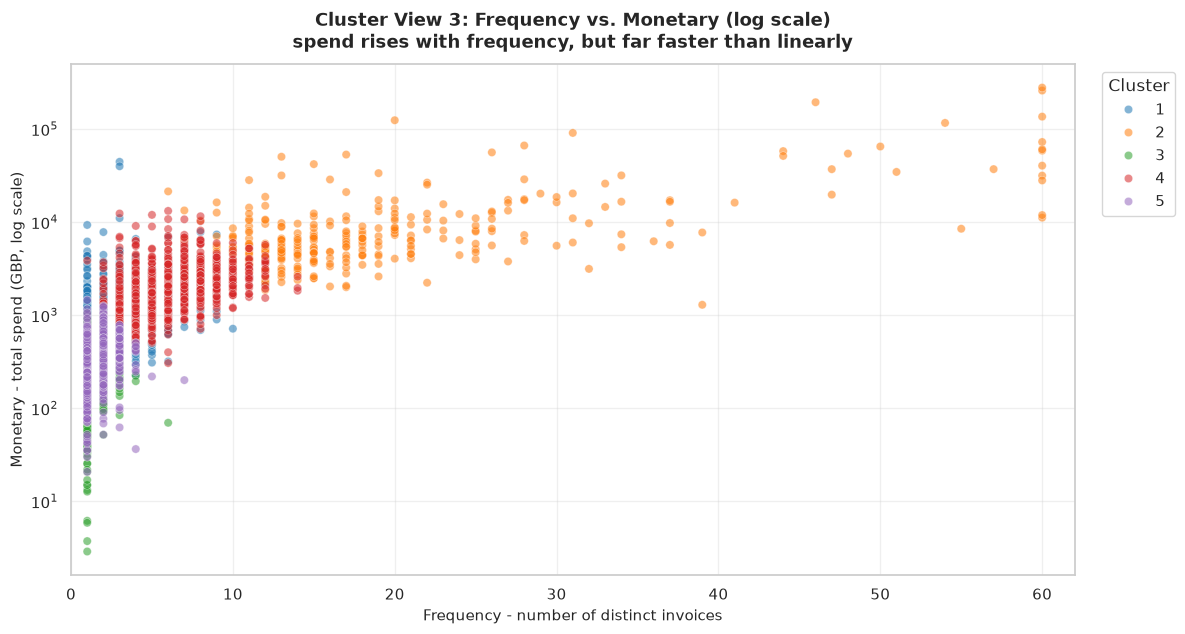

In [33]:
fig, ax = plt.subplots(figsize=(12, 6.5))
sns.scatterplot(
    data=plot_df, x="Frequency", y="Monetary", hue="Cluster", palette="tab10",
    alpha=0.55, edgecolor="white", linewidth=0.4, ax=ax,
)
ax.set_yscale("log")
ax.set_xlim(0, 62)
ax.set_title("Cluster View 3: Frequency vs. Monetary (log scale)\n"
             "spend rises with frequency, but far faster than linearly", pad=12)
ax.set_xlabel("Frequency - number of distinct invoices")
ax.set_ylabel("Monetary - total spend (GBP, log scale)")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "08_clusters_frequency_vs_monetary.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** Along the Frequency axis, total spend rises steeply: single-order customers
spend in the tens or hundreds, while 20+ order customers spend in the tens of thousands. Because
the y-axis is logarithmic, the relationship is close to a straight line - i.e. **Monetary grows
roughly exponentially with Frequency**.

**Why it matters.** The correct commercial lever is therefore **order frequency**, not order
value. Raising the number of orders a customer places is worth far more than raising the size of
any single order, and the most efficient way to do that is to increase *active months* - the
Champions are active in 9.7 of the 12 months, which is exactly the behaviour to copy.

## 13. Segment Size and Revenue Contribution

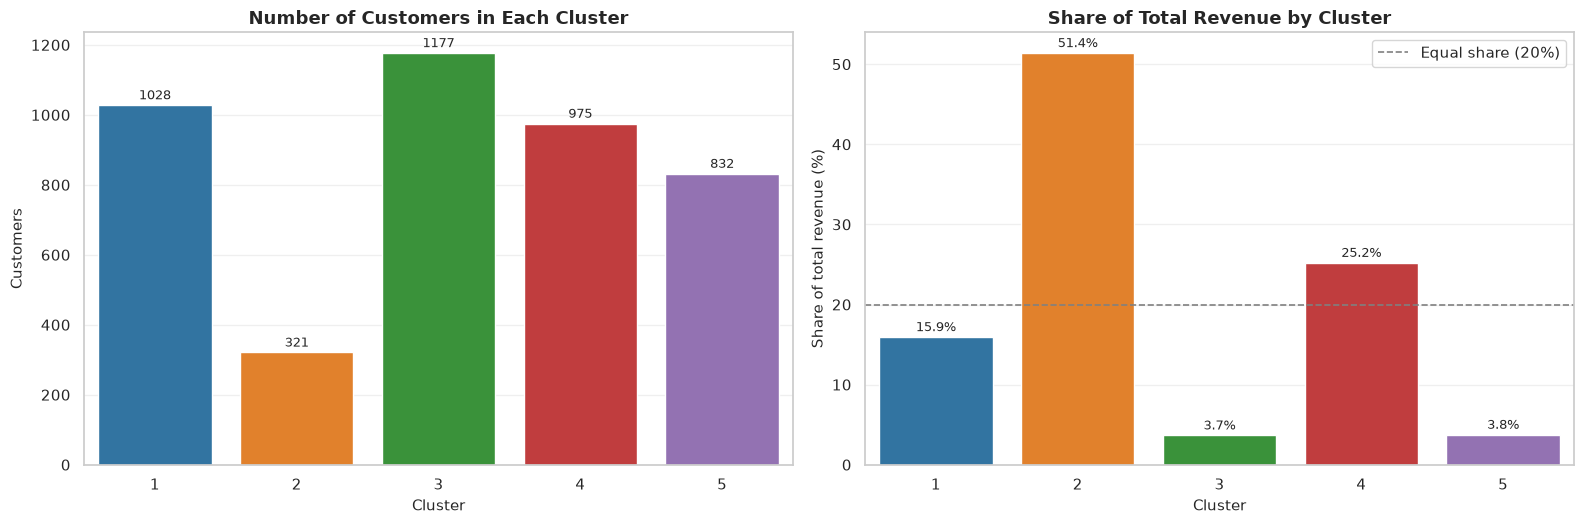

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.4))

order = cluster_profile.sort_values("Avg_Monetary", ascending=False)

sns.barplot(data=order, x="Cluster", y="Customers", palette="tab10", ax=axes[0])
axes[0].set_title("Number of Customers in Each Cluster")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Customers")
for container in axes[0].containers:
    axes[0].bar_label(container, padding=2, fontsize=9)

sns.barplot(data=order, x="Cluster", y="Revenue_Share_%", palette="tab10", ax=axes[1])
axes[1].set_title("Share of Total Revenue by Cluster")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Share of total revenue (%)")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", padding=2, fontsize=9)
axes[1].axhline(20, color="grey", linestyle="--", linewidth=1.2, label="Equal share (20%)")
axes[1].legend(frameon=True)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "09_cluster_size_vs_revenue_share.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** Customer count and revenue contribution are almost mirror images. The
largest segment by headcount (Dormant, 1,177 customers = 27.16%) contributes 3.67% of revenue,
while the smallest segment by headcount (Champions, 321 customers = 7.41%) contributes 51.41%.

**Why it matters.** Any marketing budget allocated by customer count would send roughly half of
it to customers who cannot generate a return. Budget must follow revenue contribution, and
headcount is actively misleading.

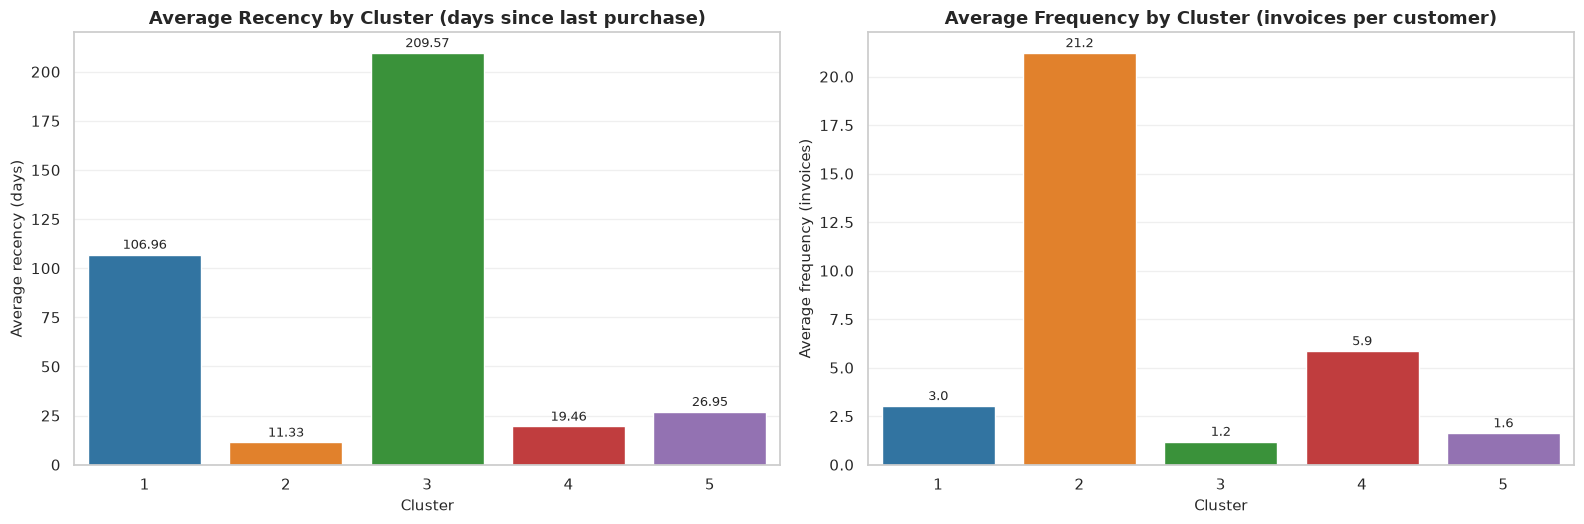

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.4))

order2 = cluster_profile.sort_values("Avg_Recency_Days", ascending=False)

sns.barplot(data=order2, x="Cluster", y="Avg_Recency_Days", palette="tab10", ax=axes[0])
axes[0].set_title("Average Recency by Cluster (days since last purchase)")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Average recency (days)")
for container in axes[0].containers:
    axes[0].bar_label(container, padding=2, fontsize=9)

sns.barplot(data=order2, x="Cluster", y="Avg_Frequency", palette="tab10", ax=axes[1])
axes[1].set_title("Average Frequency by Cluster (invoices per customer)")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Average frequency (invoices)")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f", padding=2, fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "10_recency_and_frequency_by_cluster.png", dpi=150, bbox_inches="tight")
plt.show()

## 14. Validating the Clustering Against the Classical RFM Scores

Because the clusters were produced *without* using any RFM score, they can be cross-checked
against the independent quintile scoring from section 7.2. Agreement between the two methods is
evidence that the segmentation reflects genuine behaviour rather than a clustering artefact.

In [36]:
# Both Series must share the same index (CustomerID) so that pandas aligns them correctly
kmeans_segment_series = pd.Series(
    [SEGMENT_NAMES[c] for c in clustered_customers["Cluster"]],
    index=clustered_customers.index,
    name="KMeans_Segment",
)
rfm_segment_series = rfm_scores.loc[clustered_customers.index, "RFM_Segment"]

cross_tab = pd.crosstab(kmeans_segment_series, rfm_segment_series)
print("K-Means segment  (rows)  vs  classical quintile RFM segment  (columns)")
print(cross_tab.to_string())
cross_tab.to_csv(OUTPUT_DIR / "kmeans_vs_rfm_crosstab.csv")

K-Means segment  (rows)  vs  classical quintile RFM segment  (columns)
RFM_Segment               Champions  Dormant  Loyal  Recent
KMeans_Segment                                             
At-Risk High-Value                8      201    812       7
Champions                       306        0     15       0
Dormant Low-Value                 0     1023    154       0
Loyal Customers                 629        0    335      11
Recent Occasional Buyers          0      199    341     292


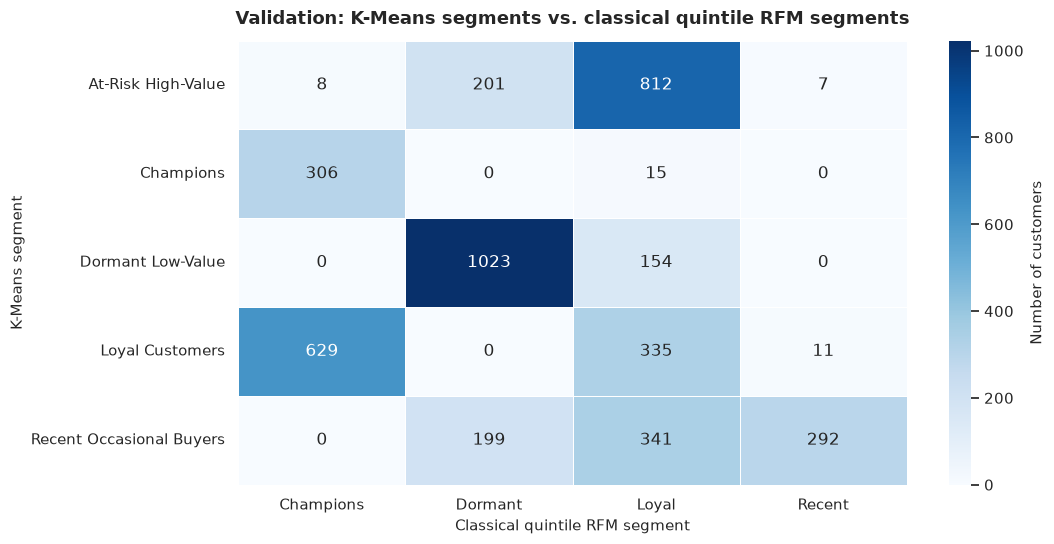

In [37]:
fig, ax = plt.subplots(figsize=(11, 5.6))
sns.heatmap(cross_tab, annot=True, fmt="d", cmap="Blues", linewidths=0.6,
            cbar_kws={"label": "Number of customers"})
ax.set_title("Validation: K-Means segments vs. classical quintile RFM segments", pad=12)
ax.set_xlabel("Classical quintile RFM segment")
ax.set_ylabel("K-Means segment")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)
ax.grid(False)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "11_validation_kmeans_vs_rfm.png", dpi=150, bbox_inches="tight")
plt.show()

**What this shows.** The two independent methods agree strongly. **306 of the 321 K-Means Champions
are also quintile `Champions` customers, and 1,023 of the 1,177 K-Means Dormant customers are
quintile `Dormant` (zero of them fall in the top quintile).** The only systematic disagreement is
the `Loyal Customers` group, which the quintile rule splits across `Champions` (629), `Loyal`
(335) and `Recent` (11) because a 20% forced-size rule cannot express "good on both dimensions".
The `Recent Occasional Buyers` group shows the mirror-image split: 292 land in `Recent` but 199
land in `Dormant`, because a 26.95-day recency is recent in absolute terms yet low against the
base rate of 50 days. The agreement is not perfect - expected, since quintiles force every
segment to contain exactly 20% of customers while K-Means lets the segments differ in size.

**Why it matters.** This is a genuine validation, not a restatement: K-Means, run on
log-scaled raw behaviour, independently rediscovers the structure that a hand-crafted scoring
rule produces. That gives confidence the segments are real.

## 15. Segment Business Names and Marketing Recommendations

In [38]:
segment_summary = cluster_profile.copy()
segment_summary["Segment"] = [SEGMENT_NAMES[i] for i in segment_summary.index]
segment_summary = segment_summary[
    ["Segment", "Customers", "Customer_Share_%", "Revenue_Share_%", "Avg_Recency_Days",
     "Avg_Frequency", "Avg_Monetary", "Avg_Basket_Value", "Active_Months"]
]
segment_summary.to_csv(OUTPUT_DIR / "segment_summary.csv")

print("SEGMENT SUMMARY TABLE")
print(segment_summary.to_string())

SEGMENT SUMMARY TABLE
                          Segment  Customers  Customer_Share_%  Revenue_Share_%  Avg_Recency_Days  Avg_Frequency  Avg_Monetary  Avg_Basket_Value  Active_Months
Cluster                                                                                                                                                        
2                       Champions        321              7.41            51.41             11.33          21.22     13,600.93            589.65           9.75
4                 Loyal Customers        975             22.50            25.22             19.46           5.86      2,196.35            406.45           4.66
1              At-Risk High-Value       1028             23.72            15.95            106.96           3.03      1,317.34            541.45           2.66
5        Recent Occasional Buyers        832             19.20             3.75             26.95           1.63        382.92            259.52           1.52
3               Do

In [39]:
recommendations = pd.DataFrame([
    {
        "Segment": "Champions",
        "Size": "321 customers (7.41%)",
        "Revenue role": "51.41% of all revenue - the profit engine",
        "Profile": "Recency 11.33 days, 21.22 invoices, 13,600.93 total spend, active 9.75 of 12 months",
        "Objective": "Protect and grow. Never lose them; increase their basket.",
        "Recommended action": [
            "Assign a named account manager or VIP concierge contact.",
            "Early access to new products and a dedicated VIP support line.",
            "Loyalty points or tier benefits rather than discounts - they are already the "
            "highest-value customers, so protect margin instead of training them to wait for deals.",
            "Ask for referrals and testimonials: 321 advocates is the cheapest acquisition channel available.",
            "Monitor monthly: any increase in this cluster's Recency above 30 days is an early warning sign.",
        ],
    },
    {
        "Segment": "Loyal Customers",
        "Size": "975 customers (22.50%)",
        "Revenue role": "25.22% of all revenue - the stable core",
        "Profile": "Recency 19.46 days, 5.86 invoices, 2,196.35 total spend, active 4.66 of 12 months",
        "Objective": "Convert into Champions by increasing purchase frequency.",
        "Recommended action": [
            "Targeted cross-sell of higher-margin categories - these customers already buy regularly.",
            "Subscription or replenishment reminders to raise active months from 4.66 towards 9.75.",
            "Spend-threshold vouchers (e.g. 'spend 100 more, get free delivery') to lift basket value, "
            "instead of blanket percentage discounts.",
            "Invite to the loyalty programme: this segment has the clearest upgrade path.",
        ],
    },
    {
        "Segment": "At-Risk High-Value",
        "Size": "1,028 customers (23.72%)",
        "Revenue role": "15.95% of all revenue - the biggest recoverable loss",
        "Profile": "Recency 106.96 days, 3.03 invoices, 1,317.34 total spend (0.67x the base average, but 5.0x the Dormant segment)",
        "Objective": "Win back before they become dormant. Highest priority after Champions.",
        "Recommended action": [
            "Trigger a win-back campaign at 60-90 days of inactivity - this is exactly where this segment sits.",
            "Personalised reactivation email referencing their actual past purchases.",
            "Use a modest incentive (free delivery or a small targeted offer), not a blanket discount.",
            "Have the retention team review the top 100 by historical value individually.",
            "Track a 90-day reactivation rate; if this segment is not contacted, this revenue is lost for good.",
        ],
    },
    {
        "Segment": "Recent Occasional Buyers",
        "Size": "832 customers (19.20%)",
        "Revenue role": "3.75% of all revenue - low current value, unproven potential",
        "Profile": "Recency 26.95 days, 1.63 invoices, 382.92 total spend, active 1.52 of 12 months",
        "Objective": "Convert single buyers into repeat buyers - the cheapest growth available.",
        "Recommended action": [
            "Aimed at second-purchase conversion: complementary product recommendations based on "
            "their first order.",
            "Automated post-purchase flow at 14-21 days offering related items.",
            "Time-limited second-order incentive, since a modest discount here is profitable "
            "(they are not a high-value at-risk group yet).",
            "Watch carefully: if they do not convert to a second order within 90 days they will "
            "drift into the Dormant segment.",
        ],
    },
    {
        "Segment": "Dormant Low-Value",
        "Size": "1,177 customers (27.16%)",
        "Revenue role": "3.67% of all revenue - the weakest return on effort",
        "Profile": "Recency 209.57 days, 1.19 invoices, 264.58 total spend, active 1.15 of 12 months",
        "Objective": "Minimise cost, not maximise revenue. This is a suppression list.",
        "Recommended action": [
            "Exclude from high-cost broadcast campaigns and paid-acquisition lookalike targeting.",
            "Use only low-cost automated email (e.g. a 12-month anniversary reactivation) - do not "
            "spend human effort or premium channel spend on them.",
            "If a reactivation email does not produce a purchase within 30 days, suppress permanently "
            "and reallocate the budget to the At-Risk High-Value segment.",
            "Their 1.19 invoices at 264.58 mean there is no profitable offer that recovers their "
            "past value - the maths does not support spending on them.",
        ],
    },
])

for _, row in recommendations.iterrows():
    print("=" * 78)
    print(f"SEGMENT: {row['Segment']}")
    print(f"  Size          : {row['Size']}")
    print(f"  Revenue role  : {row['Revenue role']}")
    print(f"  Profile       : {row['Profile']}")
    print(f"  Objective     : {row['Objective']}")
    print("  Actions       :")
    for action in row["Recommended action"]:
        print(f"    - {action}")
print("=" * 78)

SEGMENT: Champions
  Size          : 321 customers (7.41%)
  Revenue role  : 51.41% of all revenue - the profit engine
  Profile       : Recency 11.33 days, 21.22 invoices, 13,600.93 total spend, active 9.75 of 12 months
  Objective     : Protect and grow. Never lose them; increase their basket.
  Actions       :
    - Assign a named account manager or VIP concierge contact.
    - Early access to new products and a dedicated VIP support line.
    - Loyalty points or tier benefits rather than discounts - they are already the highest-value customers, so protect margin instead of training them to wait for deals.
    - Ask for referrals and testimonials: 321 advocates is the cheapest acquisition channel available.
    - Monitor monthly: any increase in this cluster's Recency above 30 days is an early warning sign.
SEGMENT: Loyal Customers
  Size          : 975 customers (22.50%)
  Revenue role  : 25.22% of all revenue - the stable core
  Profile       : Recency 19.46 days, 5.86 invoices, 2

## 16. Saving the Results

The customer-level segment assignment is saved so that a marketing team can upload it directly
into a CRM, together with the cluster centroids needed to score new customers later.

In [40]:
clustered_customers.reset_index().to_csv(
    OUTPUT_DIR / "customer_segments.csv", index=False
)
cluster_profile.reset_index().to_csv(OUTPUT_DIR / "cluster_profile_full.csv", index=False)
centroids.to_csv(OUTPUT_DIR / "cluster_centroids_log_space.csv")

print("Saved files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(f"  {path.name:<46} {path.stat().st_size / 1024:9.1f} KB")

print(f"\nclustered_customers: {clustered_customers.shape[0]:,} rows x "
      f"{clustered_customers.shape[1]} columns")
print(clustered_customers.head(5).to_string())

Saved files:
  01_missing_values_raw.png                           30.4 KB
  02_rfm_distributions.png                            83.3 KB
  03_effect_of_log_transform.png                      64.8 KB
  04_elbow_and_silhouette.png                        166.2 KB
  05_cluster_balance_raw_vs_log.png                   61.5 KB
  06_clusters_recency_vs_frequency.png               253.1 KB
  07_clusters_recency_vs_monetary.png                514.4 KB
  08_clusters_frequency_vs_monetary.png              198.9 KB
  09_cluster_size_vs_revenue_share.png                75.6 KB
  10_recency_and_frequency_by_cluster.png             83.6 KB
  11_validation_kmeans_vs_rfm.png                     87.3 KB
  cleaning_log.csv                                     0.5 KB
  cluster_centroids_log_space.csv                      0.1 KB
  cluster_profile.csv                                  0.6 KB
  cluster_profile_full.csv                             0.6 KB
  customer_segments.csv                              157.

## 17. Conclusions

In [41]:
conclusions = [
    "1.  THE CLEANING STAGE IS THE MOST IMPORTANT PART OF THIS PROJECT.\n"
    "    27.8% of the 541,909 raw rows are unusable for customer analysis - 135,080 of them are\n"
    "    guest checkouts with no CustomerID, 8,905 are cancellation credit notes still present at\n"
    "    that stage, and 5,187 more are exact duplicates. The final, trustworthy history is\n"
    "    391,148 order lines, 18,400 invoices and 4,333 customers.",

    "2.  FEATURE ENGINEERING, NOT THE ALGORITHM, DECIDED THE OUTCOME.\n"
    "    Frequency and Monetary are skewed by 11.95 and 20.92. On raw standardised features\n"
    "    K-Means does not segment customers at all - it produces a 4,309 vs 24 split at k=2 and\n"
    "    clusters of 2-24 customers at every k. After log1p the same algorithm produces five\n"
    "    balanced, campaignable groups. Preprocessing made the difference between a useless and\n"
    "    a useful analysis.",

    "3.  k = 5 IS A JUDGEMENT CALL, AND IT IS STATED AS ONE.\n"
    "    No metric selects k=5 outright: silhouette peaks at k=2 (0.4331) and, among k>=3, at k=4\n"
    "    (0.3382), while the inertia curve shows smooth diminishing returns rather than a sharp\n"
    "    elbow (16.4% into k=5, 13.4% into k=6, 10.7% into k=7). k=5 was chosen because it costs\n"
    "    only 0.02 of silhouette versus k=4 while separating 'recent loyal' from 'lapsing\n"
    "    high-value' - the merge that would hide the most recoverable revenue. The smallest\n"
    "    segment still holds 321 customers.",

    "4.  REVENUE IS EXTREMELY CONCENTRATED.\n"
    "    321 Champions (7.41% of customers) generate 51.41% of total revenue. Conversely, the\n"
    "    1,177 Dormant customers (27.16% of the base, the largest group by headcount) generate\n"
    "    only 3.67%. Headcount and value point in opposite directions.",

    "5.  THE SINGLE BIGGEST OPPORTUNITY IS THE AT-RISK SEGMENT.\n"
    "    1,028 customers (23.72%) hold 15.95% of revenue and have not bought for 106.96 days on\n"
    "    average after previously buying repeatedly. Their average spend of 1,317.34 is 0.67x the\n"
    "    base average but 5.0x the Dormant segment, so they are the best-paying population that is\n"
    "    going quiet - the one group where spend can be recovered rather than created.",

    "6.  FREQUENCY, NOT BASKET SIZE, IS THE LEVER.\n"
    "    On a log scale, Monetary rises almost linearly with Frequency. Champions are active in\n"
    "    9.75 of 12 months versus 1.15-1.52 months for the occasional and dormant groups. The\n"
    "    behaviour to copy is purchasing cadence, not spending per order.",

    "7.  THE SEGMENTS SURVIVE AN INDEPENDENT CHECK.\n"
    "    Cross-tabulating the K-Means labels against classical quintile RFM scores shows strong\n"
    "    agreement, confirming the structure is a property of the customer behaviour rather than\n"
    "    of the algorithm.",
]

for line in conclusions:
    print(line + "\n")

1.  THE CLEANING STAGE IS THE MOST IMPORTANT PART OF THIS PROJECT.
    27.8% of the 541,909 raw rows are unusable for customer analysis - 135,080 of them are
    guest checkouts with no CustomerID, 8,905 are cancellation credit notes still present at
    that stage, and 5,187 more are exact duplicates. The final, trustworthy history is
    391,148 order lines, 18,400 invoices and 4,333 customers.

2.  FEATURE ENGINEERING, NOT THE ALGORITHM, DECIDED THE OUTCOME.
    Frequency and Monetary are skewed by 11.95 and 20.92. On raw standardised features
    K-Means does not segment customers at all - it produces a 4,309 vs 24 split at k=2 and
    clusters of 2-24 customers at every k. After log1p the same algorithm produces five
    balanced, campaignable groups. Preprocessing made the difference between a useless and
    a useful analysis.

3.  k = 5 IS A JUDGEMENT CALL, AND IT IS STATED AS ONE.
    No metric selects k=5 outright: silhouette peaks at k=2 (0.4331) and, among k>=3, at k=4
    

## 18. Limitations

These limitations are real and should be stated in any presentation of this work.

1. **The dataset is twelve months old and is a 2010-2011 snapshot.** Behaviour patterns may not
   reflect the current market, and the business is a UK giftware retailer, so results may not
   transfer to other sectors.
2. **27.8% of the data could not be used.** The 135,080 guest checkouts are real revenue that is
   invisible to this analysis. Any segmentation is therefore built on *known* customers only,
   and the true customer base is larger than 4,333.
3. **Only three features were clustered.** Recency, Frequency and Monetary capture value and
   cadence but say nothing about *what* is bought, the channel used, geography (although 89.19% of order
   lines ship to the United Kingdom), or acquisition source. Adding product-category breadth and channel
   would likely split the current segments further.
4. **K-Means assumes spherical, similarly sized clusters.** The silhouette score of 0.3167
   (and a silhouette maximum of 0.4331 at k=2)
   confirms the clusters overlap. Customers near a boundary genuinely belong to two segments,
   and the assignment is a probabilistic judgement, not a fact.
5. **Five clusters is a modelling choice, not a discovered truth.** k=4, k=5 and k=6 are all
   defensible from the diagnostics. k=5 was selected for business usefulness and this is a
   judgement, documented in section 9, not a fact recovered from the data.
6. **The extreme tail was transformed, not removed.** A few wholesale customers (one has 206
   invoices and 279,138.02 in spend) still sit far outside the normal distribution. The log
   transform limits their influence but does not eliminate it, and they are inside the
   Champions cluster.
7. **No causal or predictive claim is made.** The recommendations are hypotheses derived from
   the observed segments. A campaign targeting the At-Risk segment must be A/B tested; this
   notebook cannot prove that it will work.
8. **Recency is measured against a snapshot of 2011-12-10**, not against today. The numbers are
   internally consistent, but they cannot be reused as live KPIs.

## 19. Outputs Generated by This Notebook

| File | Content |
|---|---|
| `01_missing_values_raw.png` | Missing-value map of the raw file |
| `02_rfm_distributions.png` | Recency / Frequency / Monetary distributions |
| `03_effect_of_log_transform.png` | Box plots before and after `log1p` |
| `04_elbow_and_silhouette.png` | Elbow curve and silhouette score by *k* |
| `05_cluster_balance_raw_vs_log.png` | Smallest-cluster size, raw vs log features |
| `06_clusters_recency_vs_frequency.png` | Cluster scatter 1 (Recency vs Frequency) |
| `07_clusters_recency_vs_monetary.png` | Cluster scatter 2 (Recency vs Monetary) |
| `08_clusters_frequency_vs_monetary.png` | Cluster scatter 3 (Frequency vs Monetary) |
| `09_cluster_size_vs_revenue_share.png` | Cluster bar chart and revenue share |
| `10_recency_and_frequency_by_cluster.png` | Recency and frequency per cluster |
| `11_validation_kmeans_vs_rfm.png` | Validation heatmap vs classical RFM |
| `cleaning_log.csv` | Row counts before/after every cleaning step |
| `k_selection_metrics.csv` | Inertia, silhouette and cluster size for every *k* |
| `cluster_profile.csv` | The cluster profile table |
| `cluster_profile_full.csv` | Full cluster profile with all metrics |
| `segment_summary.csv` | Named segment summary |
| `customer_segments.csv` | **Customer-level segment assignment (CRM-ready)** |
| `cluster_centroids_log_space.csv` | Centroids for scoring new customers |
| `kmeans_vs_rfm_crosstab.csv` | Validation cross-tabulation |

In [42]:
assert cluster_profile["Customers"].sum() == len(clustered_customers)
assert clustered_customers["Cluster"].nunique() == K
assert clustered_customers.notna().all().all()

print("FINAL SANITY CHECKS PASSED")
print(f"  Customers clustered      : {len(clustered_customers):,}")
print(f"  Clusters produced        : {clustered_customers['Cluster'].nunique()}")
print(f"  Total revenue covered    : {clustered_customers['Monetary'].sum():,.2f}")
print(f"  Smallest cluster         : {cluster_profile['Customers'].min():,} customers")
print(f"  Cluster balance          : {cluster_profile['Customers'].min() / len(clustered_customers) * 100:.1f}% "
      f"to {cluster_profile['Customers'].max() / len(clustered_customers) * 100:.1f}%")
print("\nNotebook completed successfully.")

FINAL SANITY CHECKS PASSED
  Customers clustered      : 4,333
  Clusters produced        : 5
  Total revenue covered    : 8,491,574.44
  Smallest cluster         : 321 customers
  Cluster balance          : 7.4% to 27.2%

Notebook completed successfully.
